# Image Histogram

บทเรียนนี้อธิบาย histogram ของภาพ ตั้งแต่แนวคิดพื้นฐาน การคำนวณด้วยตนเอง การใช้ OpenCV ไปจนถึงการปรับปรุง contrast ด้วย histogram processing เหมาะสำหรับนักศึกษาปริญญาตรีที่เริ่มเรียน image processing

**เป้าหมายการเรียนรู้**

- อธิบายได้ว่า histogram ของภาพคืออะไร และบอกข้อมูลอะไรเกี่ยวกับภาพ
- คำนวณ grayscale histogram ได้ทั้งแบบเขียนเองและใช้ OpenCV
- เข้าใจ probability histogram และ cumulative distribution function (CDF)
- ทดลองทำ contrast stretching, histogram equalization และ CLAHE ได้
- อ่านไฟล์ภาพอย่างปลอดภัย โดยตรวจสอบว่า `cv2.imread()` อ่านภาพสำเร็จหรือไม่


## 1. Histogram ของภาพคืออะไร

Histogram ของภาพคือกราฟที่นับจำนวนพิกเซลในแต่ละระดับความเข้ม สำหรับภาพ grayscale 8-bit ค่าพิกเซลอยู่ในช่วง 0 ถึง 255

- ค่าใกล้ 0 หมายถึงมืดหรือดำ
- ค่าใกล้ 255 หมายถึงสว่างหรือขาว
- แกน x คือระดับความเข้มของพิกเซล
- แกน y คือจำนวนพิกเซลที่มีค่านั้น

ถ้าให้ `h(k)` แทนจำนวนพิกเซลที่มีค่าความเข้มเท่ากับ `k`

$$
h(k) = \#\{(x,y) \mid I(x,y)=k\}
$$

Histogram ช่วยบอกภาพรวมของความมืด สว่าง และ contrast ของภาพ แต่มีข้อจำกัดสำคัญคือ **histogram ไม่เก็บตำแหน่งของพิกเซล** ดังนั้นภาพคนละภาพอาจมี histogram ใกล้เคียงกันได้


## 2. เตรียมไลบรารี

ใช้ `OpenCV` สำหรับอ่านและประมวลผลภาพ, `NumPy` สำหรับคำนวณ array และ `Matplotlib` สำหรับแสดงภาพ/กราฟใน notebook


In [14]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


## 3. ฟังก์ชันช่วยสำหรับบทเรียน

ฟังก์ชันชุดนี้ช่วยให้ code cell ถัดไปสั้นและอ่านง่ายขึ้น โดยมีทั้งการแสดงภาพหลายภาพ การ plot histogram การสร้างภาพตัวอย่าง และการอ่านภาพแบบปลอดภัย


In [ ]:
def show_images(images, titles=None, figsize=(14, 4)):
    """แสดงภาพหลายภาพใน notebook"""
    if titles is None:
        titles = [""] * len(images)

    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), i)
        if img.ndim == 2:
            plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def plot_hist(hist, title="Histogram", color="black"):
    """plot histogram ขนาด 256 bins"""
    plt.figure(figsize=(7, 3))
    plt.plot(hist, color=color)
    plt.title(title)
    plt.xlabel("Pixel intensity")
    plt.ylabel("Frequency")
    plt.xlim([0, 255])
    plt.grid(alpha=0.25)
    plt.show()


def create_demo_image(size=256):
    """สร้างภาพตัวอย่างสำหรับทดลอง histogram เมื่อไม่มีไฟล์ภาพจริง"""
    x = np.linspace(0, 255, size, dtype=np.uint8)
    gradient = np.tile(x, (size, 1))

    img = gradient.copy()
    cv2.rectangle(img, (25, 35), (105, 125), 40, -1)
    cv2.rectangle(img, (145, 40), (230, 135), 210, -1)
    cv2.circle(img, (80, 190), 38, 120, -1)
    cv2.putText(img, "HIST", (132, 210), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 20, 3)
    return img


def read_image(fp, flags=cv2.IMREAD_COLOR):
    """อ่านภาพด้วย OpenCV และแจ้ง error ถ้าไม่พบไฟล์หรืออ่านไม่ได้"""
    img = cv2.imread(str(fp), flags)  # str(fp) is cast "path obj" to str 
    if img is None:
        raise FileNotFoundError(f"ไม่พบไฟล์ภาพ: {fp}") # if img is None will raise err not return img
    return img # read by cv2 (b-g-r) and we should be convert to (r-g-b)


## 4. อ่านภาพตัวอย่างอย่างปลอดภัย

หลังใช้ `cv2.imread()` ต้องตรวจสอบเสมอว่าได้ภาพจริงหรือไม่ เพราะถ้าระบุ path ผิด OpenCV จะคืนค่า `None` ทำให้เกิด error ภายหลัง เช่นเรียก `.shape` กับค่า `None`

ในตัวอย่างนี้จะพยายามอ่าน `images/cameraman.png` ก่อน ถ้าไม่พบไฟล์ จะจับ `FileNotFoundError` แบบกระชับ แล้วใช้ภาพ demo ที่สร้างจากโค้ดแทน


อ่านไฟล์ภาพสำเร็จ: images\cameraman.png
ขนาดภาพสี BGR: (512, 512, 3)
ขนาดภาพ grayscale: (512, 512)


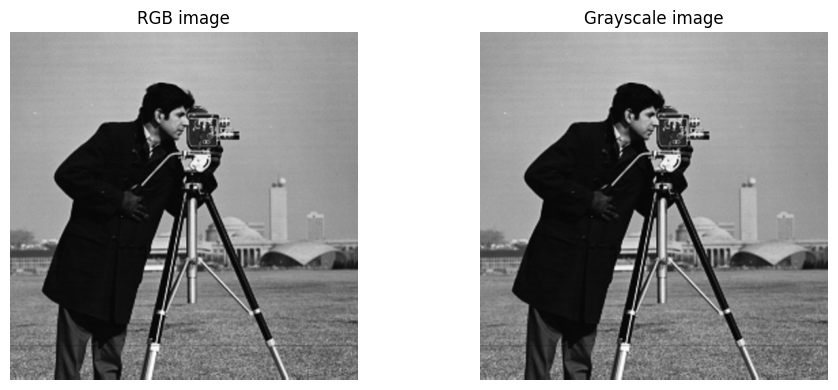

In [ ]:
fp = Path("images") / "cameraman.png" # is "path object" not str if use 

try:
    bgr = read_image(fp, cv2.IMREAD_COLOR) 
    print(f"อ่านไฟล์ภาพสำเร็จ: {fp}")
except FileNotFoundError as err:
    print(err)
    print("ใช้ภาพตัวอย่างที่สร้างจากโค้ดแทน")
    gray_demo = create_demo_image()
    bgr = cv2.cvtColor(gray_demo, cv2.COLOR_GRAY2BGR) # convert bgr -> rgb

rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

print("ขนาดภาพสี BGR:", bgr.shape)
print("ขนาดภาพ grayscale:", gray.shape)
show_images([rgb, gray], ["RGB image", "Grayscale image"], figsize=(10, 4))


## 5. Histogram แบบ Grayscale

สำหรับภาพ grayscale 8-bit เรามีระดับความเข้ม 256 ค่า คือ 0 ถึง 255 ดังนั้น histogram จะมี 256 bins

แนวคิดการนับแบบตรงไปตรงมาคือ

1. สร้าง array ความยาว 256 ที่เริ่มต้นด้วย 0
2. อ่านค่าพิกเซลทีละตัว
3. ถ้าพิกเซลมีค่า `k` ให้เพิ่ม `hist[k]` ขึ้น 1

วิธีนี้เหมาะสำหรับการเรียนรู้หลักการ แม้ในการใช้งานจริงจะนิยมใช้ `np.bincount()` หรือ `cv2.calcHist()` ที่เร็วกว่า


In [ ]:
def histogram_manual_gray(img):
    """คำนวณ histogram grayscale แบบเขียน loop เอง"""
    hist = np.zeros(256, dtype=np.int64)
    for value in img.ravel():
        hist[int(value)] += 1
    return hist


def histogram_numpy_gray(img):
    """คำนวณ histogram grayscale ด้วย NumPy"""
    return np.bincount(img.ravel(), minlength=256)


hist_manual = histogram_manual_gray(gray) # manual write
hist_numpy = histogram_numpy_gray(gray)  # use np bin count
hist_cv = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()

print("จำนวนพิกเซลทั้งหมด:", gray.size)
print("ผลรวม histogram:", hist_manual.sum())
print("manual กับ numpy เท่ากันหรือไม่:", np.array_equal(hist_manual, hist_numpy))
print("manual กับ cv2 เท่ากันหรือไม่:", np.allclose(hist_manual, hist_cv))


จำนวนพิกเซลทั้งหมด: 262144
ผลรวม histogram: 262144
manual กับ numpy เท่ากันหรือไม่: True
manual กับ cv2 เท่ากันหรือไม่: True


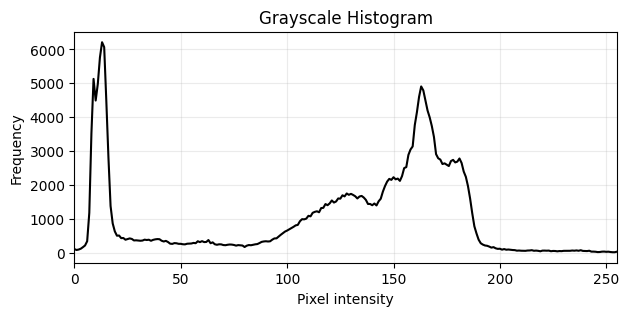

In [18]:
plot_hist(hist_manual, "Grayscale Histogram")


## 6. Probability Histogram และ CDF

Histogram ปกติเป็น “จำนวนพิกเซล” ถ้าต้องการมองเป็นสัดส่วน ให้หารด้วยจำนวนพิกเซลทั้งหมด จะได้ **probability histogram**

$$
p(k) = \frac{h(k)}{MN}
$$

เมื่อ `M x N` คือขนาดภาพ

ส่วน **CDF (Cumulative Distribution Function)** คือผลรวมสะสมของ probability histogram

$$
CDF(k) = \sum_{i=0}^{k} p(i)
$$

CDF ใช้สำคัญมากใน histogram equalization เพราะบอกว่าค่าความเข้มสะสมมาถึงระดับหนึ่งเป็นสัดส่วนเท่าไร


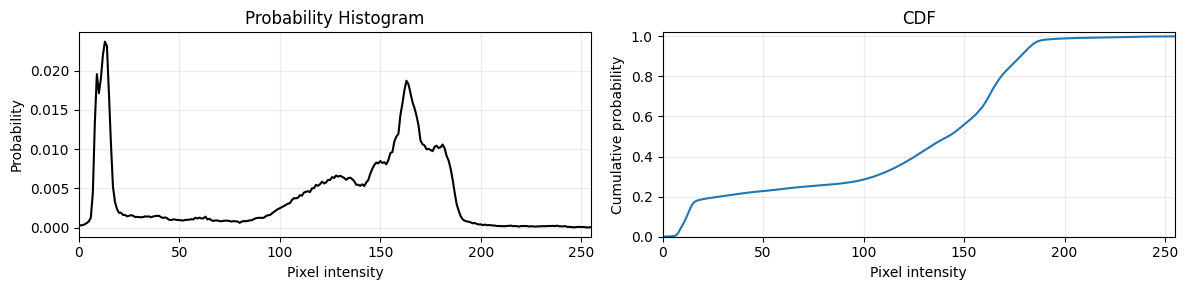

In [19]:
prob_hist = hist_manual / hist_manual.sum()
cdf = np.cumsum(prob_hist)

plt.figure(figsize=(12, 3))

plt.subplot(1, 2, 1)
plt.plot(prob_hist, color="black")
plt.title("Probability Histogram")
plt.xlabel("Pixel intensity")
plt.ylabel("Probability")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

plt.subplot(1, 2, 2)
plt.plot(cdf, color="tab:blue")
plt.title("CDF")
plt.xlabel("Pixel intensity")
plt.ylabel("Cumulative probability")
plt.xlim([0, 255])
plt.ylim([0, 1.02])
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 7. อ่านค่า Histogram เพื่อวิเคราะห์ภาพ

การดู histogram ช่วยประเมินภาพได้อย่างรวดเร็ว เช่น

- กราฟกระจุกด้านซ้าย: ภาพมืด
- กราฟกระจุกด้านขวา: ภาพสว่าง
- กราฟแคบ: contrast ต่ำ
- กราฟกระจายกว้าง: contrast สูงกว่า

อย่างไรก็ตาม histogram บอกเพียงการกระจายของค่า intensity ไม่ได้บอกว่าวัตถุอยู่ตำแหน่งใดในภาพ


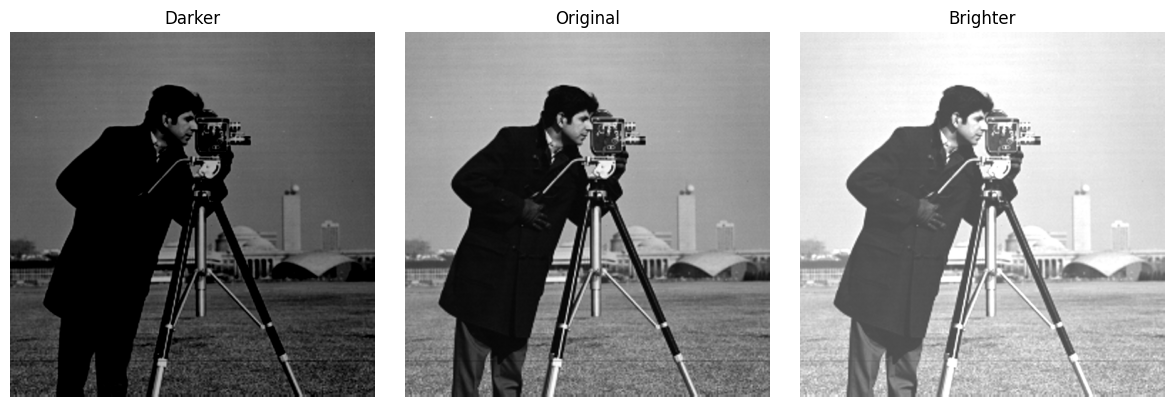

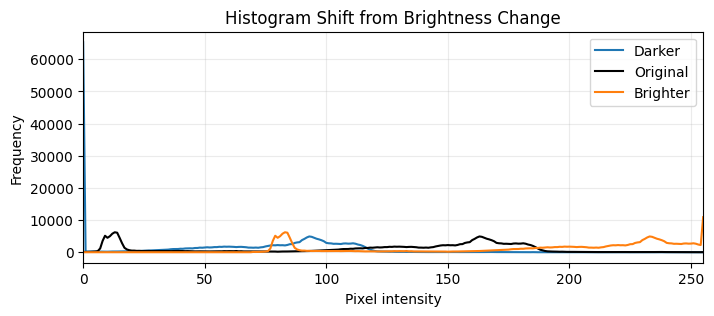

In [20]:
dark_gray = np.clip(gray.astype(np.int16) - 70, 0, 255).astype(np.uint8)
bright_gray = np.clip(gray.astype(np.int16) + 70, 0, 255).astype(np.uint8)

show_images(
    [dark_gray, gray, bright_gray],
    ["Darker", "Original", "Brighter"],
    figsize=(12, 4),
)

plt.figure(figsize=(8, 3))
plt.plot(histogram_numpy_gray(dark_gray), label="Darker", color="tab:blue")
plt.plot(histogram_numpy_gray(gray), label="Original", color="black")
plt.plot(histogram_numpy_gray(bright_gray), label="Brighter", color="tab:orange")
plt.title("Histogram Shift from Brightness Change")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 8. Contrast Stretching

Contrast stretching คือการยืดช่วงค่าความเข้มของภาพให้กว้างขึ้น เช่น จากเดิมอยู่ในช่วง 60 ถึง 180 ให้ขยายไปอยู่ในช่วง 0 ถึง 255

สูตรพื้นฐานคือ

$$
I_{out} = \frac{I - I_{min}}{I_{max} - I_{min}} \times 255
$$

วิธีนี้เข้าใจง่ายและเหมาะกับภาพที่ contrast ต่ำ แต่ถ้ามี outlier มาก อาจใช้ percentile แทน min/max จริงได้


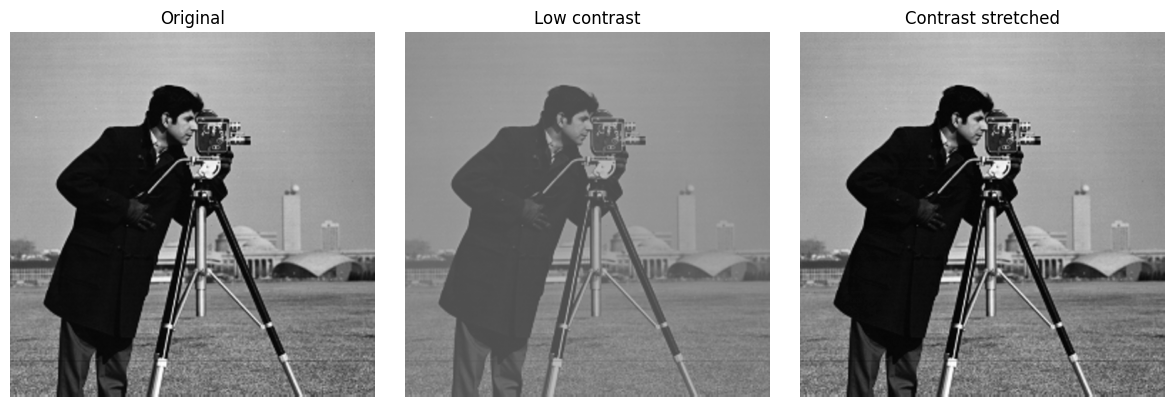

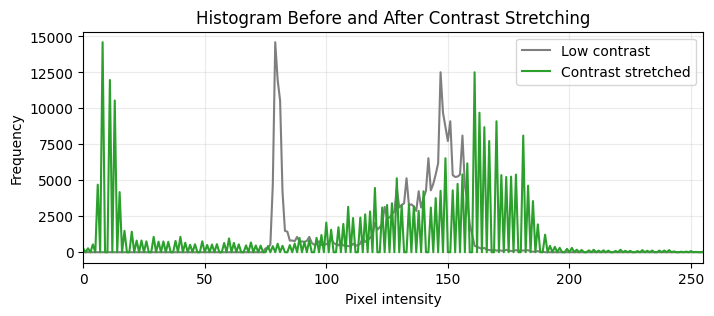

In [ ]:
def contrast_stretch(img):
    img_float = img.astype(np.float32)
    min_val, max_val = img_float.min(), img_float.max()
    if max_val == min_val:
        return np.zeros_like(img, dtype=np.uint8)
    stretched = (img_float - min_val) * 255.0 / (max_val - min_val)
    return stretched.astype(np.uint8)


low_contrast = np.clip(gray.astype(np.float32) * 0.45 + 75, 0, 255).astype(np.uint8)
stretched = contrast_stretch(low_contrast)
#stretched = contrast_stretch(gray)

show_images(
    [gray, low_contrast, stretched],
    ["Original", "Low contrast", "Contrast stretched"],
    figsize=(12, 4),
)
#print(stretched.min(),np.amax(stretched))
#hist_manual1 = histogrm_manual_gray(stretched)


plt.figure(figsize=(8, 3))
plt.plot(histogram_numpy_gray(low_contrast), label="Low contrast", color="tab:gray")
plt.plot(histogram_numpy_gray(stretched), label="Contrast stretched", color="tab:green")
plt.title("Histogram Before and After Contrast Stretching")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 9. Histogram Equalization

Histogram equalization เป็นวิธีปรับ contrast โดยใช้ CDF เพื่อกระจายค่าความเข้มให้ใช้ช่วง 0 ถึง 255 มากขึ้น

แนวคิดคือสร้าง lookup table (LUT) จาก CDF แล้วแปลงค่าพิกเซลเดิมไปเป็นค่าพิกเซลใหม่

ข้อควรระวัง: histogram equalization อาจทำให้ noise ชัดขึ้น หรือทำให้ภาพดูแข็งเกินไปในบางกรณี จึงควรดูผลลัพธ์เสมอ ไม่ใช่ใช้โดยอัตโนมัติทุกภาพ


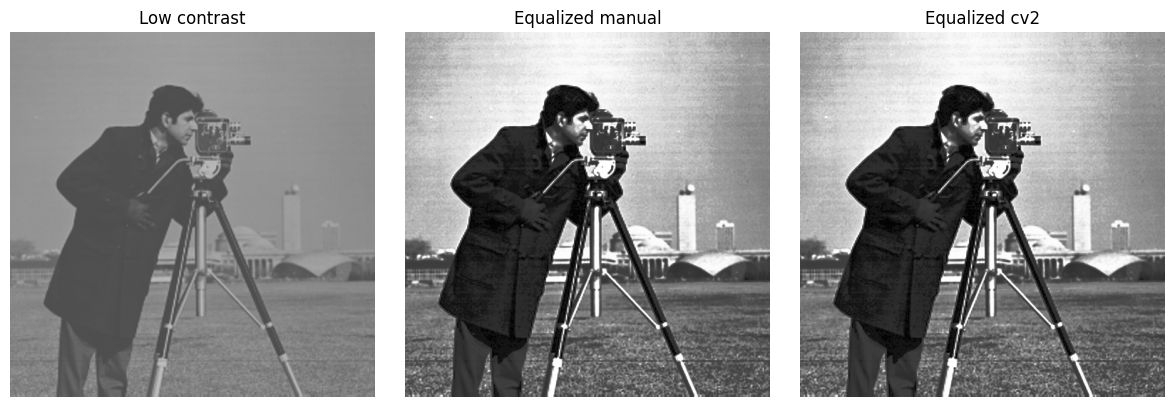

manual กับ cv2 ใกล้เคียงกันหรือไม่: True


In [22]:
def equalize_hist_manual(img):
    hist = histogram_numpy_gray(img)
    cdf = hist.cumsum()
    nonzero_cdf = cdf[cdf > 0]

    if len(nonzero_cdf) == 0:
        return np.zeros_like(img), np.arange(256, dtype=np.uint8)

    cdf_min = nonzero_cdf[0]
    total = img.size

    if total == cdf_min:
        return img.copy(), np.arange(256, dtype=np.uint8)

    lut = np.round((cdf - cdf_min) * 255 / (total - cdf_min))
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[img], lut


equalized_manual, lut = equalize_hist_manual(low_contrast)
equalized_cv = cv2.equalizeHist(low_contrast)

show_images(
    [low_contrast, equalized_manual, equalized_cv],
    ["Low contrast", "Equalized manual", "Equalized cv2"],
    figsize=(12, 4),
)

print("manual กับ cv2 ใกล้เคียงกันหรือไม่:", np.allclose(equalized_manual, equalized_cv, atol=1))


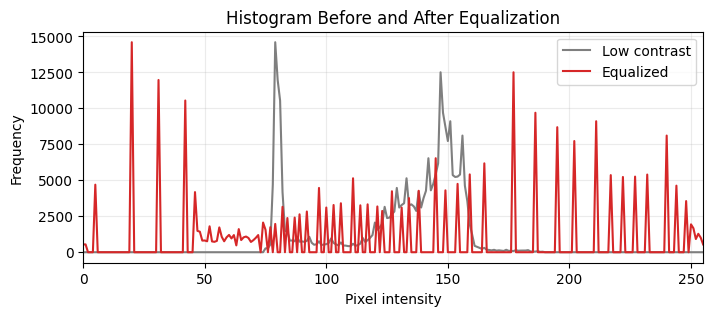

In [23]:
plt.figure(figsize=(8, 3))
plt.plot(histogram_numpy_gray(low_contrast), label="Low contrast", color="tab:gray")
plt.plot(histogram_numpy_gray(equalized_manual), label="Equalized", color="tab:red")
plt.title("Histogram Before and After Equalization")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 10. CLAHE

CLAHE ย่อมาจาก Contrast Limited Adaptive Histogram Equalization เป็นการทำ histogram equalization แบบแบ่งภาพเป็นบริเวณย่อย ๆ และจำกัดการขยาย contrast เพื่อลดปัญหา noise ถูกขยายมากเกินไป

CLAHE มักเหมาะกว่าการ equalization ทั้งภาพ เมื่อภาพมีแสงไม่สม่ำเสมอ เช่น บางบริเวณมืด บางบริเวณสว่าง


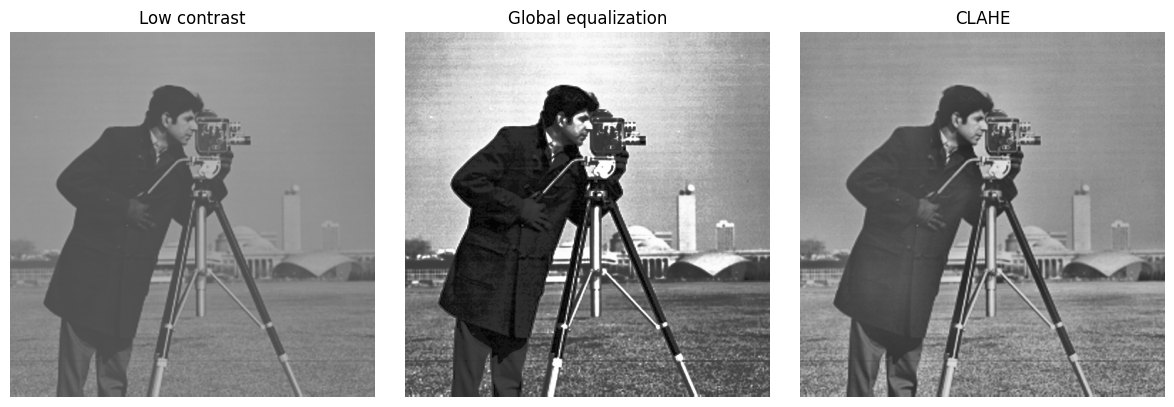

In [24]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(low_contrast)

show_images(
    [low_contrast, equalized_manual, clahe_img],
    ["Low contrast", "Global equalization", "CLAHE"],
    figsize=(12, 4),
)


## 11. Color Histogram

สำหรับภาพสี เราสามารถดู histogram แยกตาม channel ได้ เช่น RGB มี 3 channel คือ Red, Green และ Blue

Color histogram ใช้ดูการกระจายของสีในภาพ แต่ถ้าจะปรับ contrast ของภาพสี ควรระวังการ equalize แต่ละ channel แยกกัน เพราะอาจทำให้สีเพี้ยนได้ วิธีที่มักเหมาะกว่าคือปรับเฉพาะ channel ความสว่าง เช่น `Y` ในระบบสี YCrCb


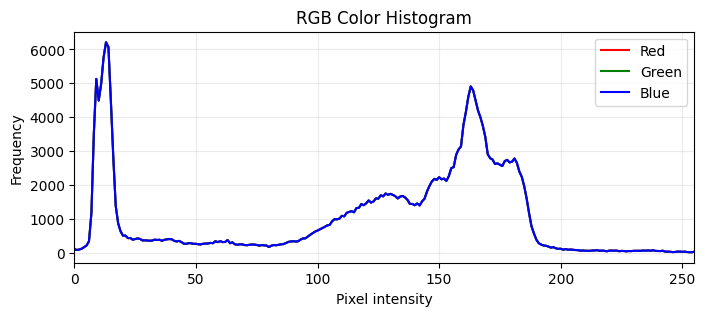

In [25]:
colors = {"Red": "red", "Green": "green", "Blue": "blue"}

plt.figure(figsize=(8, 3))
for channel_index, (name, color) in enumerate(colors.items()):
    channel_hist = histogram_numpy_gray(rgb[:, :, channel_index])
    plt.plot(channel_hist, color=color, label=name)

plt.title("RGB Color Histogram")
plt.xlabel("Pixel intensity")
plt.ylabel("Frequency")
plt.xlim([0, 255])
plt.grid(alpha=0.25)
plt.legend()
plt.show()


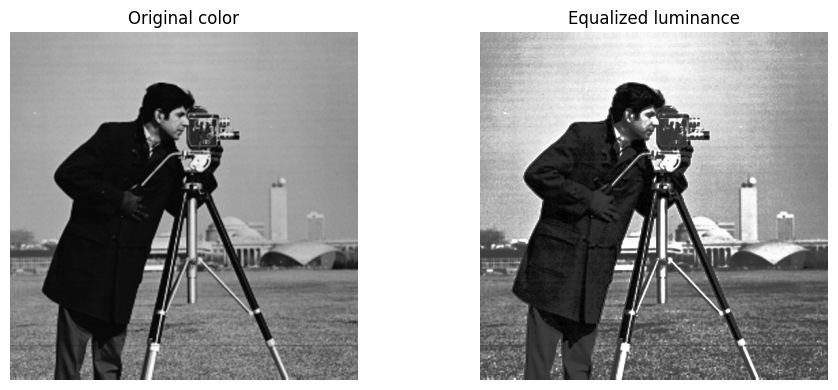

In [26]:
ycrcb = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb)
ycrcb_equalized = ycrcb.copy()
ycrcb_equalized[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])

equalized_color_bgr = cv2.cvtColor(ycrcb_equalized, cv2.COLOR_YCrCb2BGR)
equalized_color_rgb = cv2.cvtColor(equalized_color_bgr, cv2.COLOR_BGR2RGB)

show_images(
    [rgb, equalized_color_rgb],
    ["Original color", "Equalized luminance"],
    figsize=(10, 4),
)


## 12. สรุป

- Histogram คือการนับจำนวนพิกเซลในแต่ละระดับความเข้ม
- Histogram ช่วยวิเคราะห์ความมืด สว่าง และ contrast ของภาพ
- Grayscale histogram ของภาพ 8-bit มี 256 bins ตั้งแต่ 0 ถึง 255
- Probability histogram คือ histogram ที่หารด้วยจำนวนพิกเซลทั้งหมด
- CDF คือผลรวมสะสม และเป็นหัวใจของ histogram equalization
- Contrast stretching ยืดช่วงความเข้มของภาพให้กว้างขึ้น
- Histogram equalization ใช้ CDF เพื่อปรับ contrast แต่อาจทำให้ noise ชัดขึ้น
- CLAHE เหมาะกับภาพที่แสงไม่สม่ำเสมอ และควบคุมการขยาย contrast ได้ดีกว่า global equalization
- สำหรับภาพสี ควรระวังการปรับแต่ละ RGB channel แยกกัน เพราะอาจทำให้สีเพี้ยน
- ทุกครั้งที่ใช้ `cv2.imread()` ควรตรวจว่าได้ภาพจริงหรือไม่ และใช้ `try/except` รองรับกรณีไฟล์หาย

**แบบฝึกหัดสั้น ๆ**

1. เปลี่ยนภาพใน `fp` เป็นภาพอื่น แล้วสังเกต histogram
2. สร้างภาพมืดและภาพสว่างด้วยการบวก/ลบค่าพิกเซล แล้วดู histogram ที่เลื่อนไป
3. ทดลองเปลี่ยน `clipLimit` และ `tileGridSize` ของ CLAHE
4. เปรียบเทียบผลของ contrast stretching, histogram equalization และ CLAHE
5. อธิบายว่าทำไม histogram เพียงอย่างเดียวจึงไม่บอกตำแหน่งของวัตถุในภาพ


## 13. ตัวอย่างเชิงตัวเลขของการสร้างภาพ Contrast ต่ำ

ตัวอย่างนี้สร้าง array ชื่อ `gray_example` ที่มีค่าตั้งแต่ 0 ถึง 255 แล้วนำไปผ่านสูตรเดียวกับที่ใช้สร้างภาพ contrast ต่ำ

```python
np.clip(gray.astype(np.float32) * 0.45 + 75, 0, 255).astype(np.uint8)
```

แนวคิดคือคูณด้วย `0.45` เพื่อบีบช่วงค่าความเข้มให้แคบลง แล้วบวก `75` เพื่อเลื่อนช่วงค่าไปอยู่บริเวณกลาง ๆ ของช่วง 0 ถึง 255


In [27]:
gray_example = np.array([0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 255],
                        dtype=np.uint8)

low_contrast_example = np.clip(
    gray_example.astype(np.float32) * 0.45 + 75,
    0,
    255,
).astype(np.uint8)

print("gray_example:")
print(gray_example)
print("\nหลังผ่านสูตร gray * 0.45 + 75:")
print(low_contrast_example)

print("\nช่วงค่าเดิม:", gray_example.min(), "ถึง", gray_example.max())
print("ช่วงค่าหลังแปลง:", low_contrast_example.min(), "ถึง", low_contrast_example.max())


gray_example:
[  0  25  50  75 100 125 150 175 200 225 255]

หลังผ่านสูตร gray * 0.45 + 75:
[ 75  86  97 108 120 131 142 153 165 176 189]

ช่วงค่าเดิม: 0 ถึง 255
ช่วงค่าหลังแปลง: 75 ถึง 189


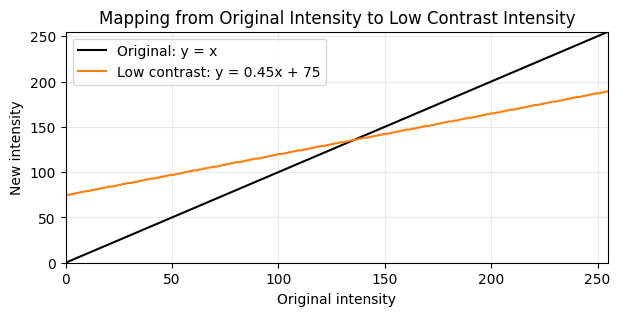

In [28]:
gray_line = np.arange(256, dtype=np.uint8)
low_contrast_line = np.clip(
    gray_line.astype(np.float32) * 0.45 + 75,
    0,
    255,
).astype(np.uint8)

plt.figure(figsize=(7, 3))
plt.plot(gray_line, gray_line, label="Original: y = x", color="black")
plt.plot(gray_line, low_contrast_line, label="Low contrast: y = 0.45x + 75", color="tab:orange")
plt.title("Mapping from Original Intensity to Low Contrast Intensity")
plt.xlabel("Original intensity")
plt.ylabel("New intensity")
plt.xlim([0, 255])
plt.ylim([0, 255])
plt.grid(alpha=0.25)
plt.legend()
plt.show()
